# M08 Overview | XNNPACK / ExecuTorch: Turning the Q/DQ Graph into a `.pte`

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m08_xnnpack_executorch/00_overview.ipynb)

All three treatments in M07 stay inside PyTorch: the Q/DQ graph goes through the reference representation, x86 lowering, and `torch.compile`, and conv is still fp32 (in an environment without mkldnn).
This chapter takes **Route A** from the [M07 overview](../m07_representation_lowering/00_overview.ipynb): hand the Q/DQ graph to ExecuTorch's XNNPACK backend, fix the int8 kernels at export time, and save a deployment file, the `.pte`.

Which layer ExecuTorch and XNNPACK each sit at (inference framework, hardware extension unit, kernel library) was covered in the first half of the M07 overview, so it is not repeated here. This chapter answers four questions:

| Question | One-line answer | notebook |
|---|---|---|
| Which `XNNPACKQuantizer` should I use? | There are two with the same name; use the executorch one to export a `.pte` | M08-1 |
| How does a Q/DQ graph become a `.pte`? | `to_edge_transform_and_lower` carves out the delegate, `to_executorch` serializes | M08-2 |
| What if XNNPACK does not support an op? | It stays outside the delegate and is run by ExecuTorch; the graph is split | M08-3 |
| Is it actually faster? | Switching runtime is already much faster; int8 must be compared against fp32 on the same runtime | M08-4 |

This chapter needs executorch (`uv sync --group executorch`).

In [1]:
#| include: false
# On Google Colab: download this tutorial's code and install the packages (takes a few minutes the first time).
# On your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "executorch==1.5.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # let the notebook import this tutorial's common/
    os.chdir(f"{repo}/en/m08_xnnpack_executorch")

In [2]:
#| echo: false
import torch

from common.pt2e import quiet  # must be imported before executorch (executorch imports torchao)
from common.data import calibration_batches
from common.env import capture_stderr
from common.models import example_inputs, get_model
from common.pt2e import convert_pt2e, prepare_pt2e
from common.viz import draw

from executorch.backends.xnnpack.partition.xnnpack_partitioner import XnnpackPartitioner  # noqa: E402
from executorch.backends.xnnpack.quantizer.xnnpack_quantizer import (  # noqa: E402
    XNNPACKQuantizer,
    get_symmetric_quantization_config,
)
from executorch.exir import to_edge_transform_and_lower  # noqa: E402
from executorch.runtime import Runtime  # noqa: E402

quiet()
_ = torch.manual_seed(0)

## A First Example: conv + relu Through the Whole Pipeline

The smallest conv + relu, from a PyTorch model all the way to execution in the ExecuTorch runtime. Below uses only the raw PyTorch, torchao, and ExecuTorch APIs, in four steps.

**Step 1: PT2E, get the Q/DQ graph.** Same flow as from M01 on, with two differences: the quantizer is the one shipped with ExecuTorch's XNNPACK backend (M08-1); and `torch.export.export` is not given `dynamic_shapes`, so the shape is fixed to batch 1 from `x` (the reason is in M08-2 C), which means the calibration data is fed one sample at a time.

In [3]:
model = get_model("conv_relu").eval()
x = example_inputs(1)                                           # batch 1

gm = torch.export.export(model, x).module()                     # static shape
quantizer = XNNPACKQuantizer().set_global(get_symmetric_quantization_config(is_per_channel=True))
prepared = prepare_pt2e(gm, quantizer)
with torch.no_grad():
    for (batch,) in calibration_batches(32):
        for i in range(len(batch)):
            prepared(batch[i : i + 1])
qdq = convert_pt2e(prepared)                                    # Q/DQ graph

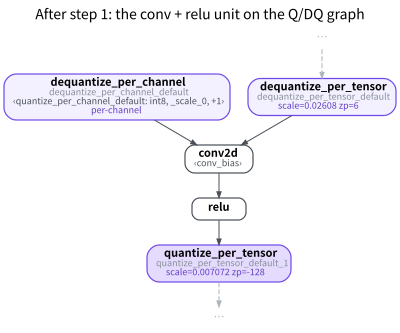

In [4]:
#| echo: false
draw(qdq, focus=["conv2d", "relu"], hops=1, title="After step 1: the conv + relu unit on the Q/DQ graph")

This is the "dq → op → q" unit from the start of the M07 overview: int8 in, int8 out, with conv and relu computed in fp32 in between.

**Step 2: lowering.** Export once more (`to_edge_transform_and_lower` takes an `ExportedProgram`, while `convert_pt2e` gives a GraphModule), then let `XnnpackPartitioner` carve out the subgraph XNNPACK can handle:

In [5]:
edge = to_edge_transform_and_lower(torch.export.export(qdq, x), partitioner=[XnnpackPartitioner()])
lowered = edge.exported_program().graph_module

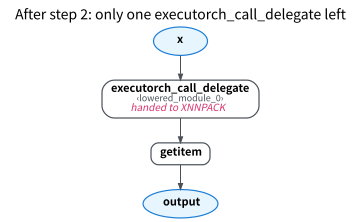

In [6]:
#| echo: false
draw(lowered, notes={"executorch_call_delegate": "handed to XNNPACK"}, title="After step 2: only one executorch_call_delegate left")

conv, relu, and q/dq are all gone, replaced by a single `executorch_call_delegate`. The `lowered_module_0` it calls is XNNPACK's delegate, which keeps the original subgraph it absorbed:

In [7]:
delegate = getattr(lowered, "lowered_module_0")
inner = delegate.original_module.graph_module                   # the subgraph absorbed into the delegate
print("backend:", delegate.backend_id)

backend: XnnpackBackend


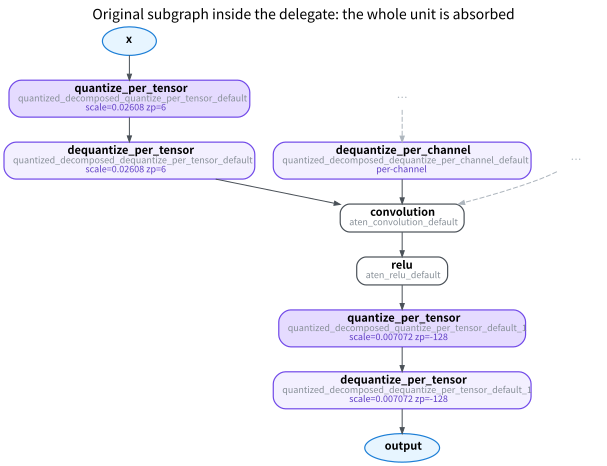

In [8]:
#| echo: false
draw(inner, focus=lambda n: n.op != "placeholder" or n.name == "x", hops=0,
     title="Original subgraph inside the delegate: the whole unit is absorbed")

The whole unit, including the weight's `dequantize_per_channel`, is inside the delegate. The names also changed: `conv2d` has already been decomposed into `convolution` in the Edge dialect.

**Step 3: serialize to a `.pte`.** `to_executorch()` does memory planning for the part of the graph outside the delegate, and `.buffer` is the bytes of the `.pte` file:

In [9]:
pte = edge.to_executorch().buffer
print(f".pte: {len(pte)} bytes")

.pte: 3872 bytes


What you hand over at deployment is these bytes (written out as a `model.pte` file).

**Step 4: run in the ExecuTorch runtime.** The first time the XNNPACK delegate is loaded, ExecuTorch's C++ layer prints a few CPU-detection log lines to stderr. They have nothing to do with the result; this project's `capture_stderr()` (`common/env.py`, not an executorch API) swallows them:

In [10]:
with capture_stderr():
    program = Runtime.get().load_program(pte)                   # a path to a .pte file also works
    forward = program.load_method("forward")
assert forward is not None
y = forward.execute([x[0]])[0]
print("output shape:", tuple(y.shape))

output shape: (1, 8, 16, 16)


`program` must be kept alive during execution: if you keep only `forward` and let `program` be garbage collected, `forward` reads freed memory when it runs.

The later notebooks use three wrappers from this project (`common/executorch_utils.py`, none of them executorch APIs):

| Wrapper | What it does |
|---|---|
| `xnnpack_ptq(model, x)` | Step 1: static-shape export, executorch's quantizer, calibration, convert |
| `lower_to_xnnpack(gm, x)` | Steps 2 and 3, returns `(edge, pte)` |
| `PteRunner(pte)` | Step 4, and keeps `program` alive |

## Terms

| Term | What it is |
|---|---|
| Edge dialect | ExecuTorch's intermediate representation: most ops are further decomposed into Core ATen ops (e.g. `conv2d` → `convolution`); the partitioner can ask to keep ops it recognizes undecomposed (e.g. `linear`; see `config_partitioner.py` in executorch 1.5.0) |
| partitioner | Finds the connected subgraphs a given backend can handle; here, `XnnpackPartitioner` |
| delegate | A piece of the graph handed to a backend, which compiles it into its own format at export time; an `executorch_call_delegate` is left on the graph |
| memory planning | `to_executorch()` decides ahead of time, from the shapes at export time, which block of memory each intermediate tensor goes in, so nothing is allocated at run time |
| `.pte` | ExecuTorch's deployment file: the graph, weights, delegate data, and memory plan are all inside |
| portable kernel | ExecuTorch's own generic C++ op implementations, which run the ops that did not go into a delegate |

## Where q/dq Go During Lowering

All the q/dq on the Q/DQ graph go into the delegate, but not every one becomes an operation. XNNPACK handles them in two ways (see `backends/xnnpack/operators/op_quant_dequant.py` and `quant_params.py` in executorch 1.5.0):

| On the Q/DQ graph | In XNNPACK |
|---|---|
| q, dq sandwiched between two ops | No operation is produced; scale and zero point are just recorded on the int8 tensor (`QuantParams.from_q_dq_node`). One unit is one int8 kernel (M08-2 A prints the nodes inside the delegate) |
| q at the graph input, dq at the output | Become fp32 ↔ int8 conversions (XNNPACK's `Convert`) |
| weight (int8 constant + per-channel scale) | Stored into the `.pte` as is |
| fp32 bias | Quantized to int32 with scale = $s_x \cdot s_w$ (`QuantParams.from_bias`) |
| ops the partitioner does not take | Stay outside the delegate and run on portable kernels (M08-3) |

So the scales XNNPACK uses are exactly the ones `convert_pt2e` wrote on the q/dq (the observer's `calculate_qparams()`). A QAT model is the same: deployment uses the scales on the converted graph, not the fake-quant buffers from training (M06-3).

## Numerical Differences from the Q/DQ Graph

Both sides get the same scale and zero point, but the outputs are still not guaranteed to be bit-identical: the Q/DQ graph simulates quantization in fp32, while XNNPACK computes with integer kernels, and rounding happens at different places.

- One known cause is the bias: on the Q/DQ graph the bias is fp32, and XNNPACK quantizes it to int32 during lowering (table above).
- Other possible sources are the integer implementations of add and mean, and how conv accumulates (inference; I did not read XNNPACK's kernel source).

These differences come from integer rounding: on executorch 1.5.0, the largest difference measured in M08-2 and M08-3 is at most 1 output LSB (1 in both on macOS arm64; 0 and 1 on Linux x86_64). So accuracy evaluated on the Q/DQ graph (M05, M06) is representative of the deployed result; just do not expect bit-identical outputs. For the comparison metrics, follow "Rules Before Comparing Backends" in the M07 overview.

## Summary and Chapter Map

- Route A decides the kernels at export time: `to_edge_transform_and_lower` has the partitioner carve out the delegate, and what the `.pte` stores is the subgraph XNNPACK will execute.
- q/dq between ops leave only the int8 tensor's scale; only the graph's input and output really convert fp32 ↔ int8.
- The `.pte` does memory planning from the shapes at export time, so this chapter uses static shapes throughout.

| notebook | Question it answers |
|---|---|
| [M08-1 Two XNNPACKQuantizers](01_executorch_vs_torchao_copy.ipynb) | How the executorch version differs from the torchao test copy; static vs dynamic specs; `set_module_name` |
| [M08-2 From Q/DQ Graph to `.pte`](02_export_to_pte.ipynb) | Graphs before and after lowering, XNNPACK nodes inside the delegate, `.pte` size, runtime execution, what happens with a different batch |
| [M08-3 Unsupported Ops](03_unsupported_ops.ipynb) | How the graph is split, what crosses the boundary, how far it is from the Q/DQ graph |
| [M08-4 latency](04_latency.ipynb) | Which is faster among eager, Q/DQ graph, fp32 `.pte`, and int8 `.pte`; the gain splits into two parts |

Deliberately skipped in this chapter: `.pte` with dynamic shapes; ExecuTorch backends other than XNNPACK (the ones listed in the M07 overview); ONNX Runtime's Route B is in M09.

## References

- ExecuTorch docs: [Backends overview](https://docs.pytorch.org/executorch/stable/backends-overview.html), [XNNPACK backend](https://docs.pytorch.org/executorch/stable/backends-xnnpack.html)
- executorch 1.5.0 source: [`backends/xnnpack/operators/op_quant_dequant.py`](https://github.com/pytorch/executorch/blob/v1.5.0/backends/xnnpack/operators/op_quant_dequant.py), [`quant_params.py`](https://github.com/pytorch/executorch/blob/v1.5.0/backends/xnnpack/operators/quant_params.py), [`backends/xnnpack/quantizer/xnnpack_quantizer.py`](https://github.com/pytorch/executorch/blob/v1.5.0/backends/xnnpack/quantizer/xnnpack_quantizer.py)
- [XNNPACK](https://github.com/google/XNNPACK)